In [11]:

# %% 0. Import & konfigurasi
from pathlib import Path
import pandas as pd
 
BASE = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep')
 
YEARS = [2022, 2023, 2024, 2025]
 
# Nama kolom (setelah dinormalisasi: huruf kecil, spasi -> underscore)
TARGET    = '_michd'
YEAR_COL  = 'iyear'
STATE_COL = '_state'
 
# Aturan pembagian data berdasarkan nilai iyear
TRAIN_YEARS = [2022, 2023]
VAL_YEAR    = 2024
TEST_YEARS   = [2025, 2026]   # 2026 digabung ke test untuk menambah data
 
SHOW_INFO = False   # True -> tampilkan d.info() untuk tiap dataset
 
 
# %% Fungsi bantu
def clean_cols(d: pd.DataFrame) -> pd.DataFrame:
    """Normalisasi nama kolom: strip, huruf kecil, spasi -> underscore."""
    d = d.copy()
    d.columns = (d.columns.astype(str)
                 .str.strip()
                 .str.lower()
                 .str.replace(r'\s+', '_', regex=True))
    return d
 
 
def print_shapes(dct: dict, judul: str) -> None:
    print(f"=== {judul} ===")
    for name, d in dct.items():
        print(f"{name}: {d.shape[0]} baris x {d.shape[1]} kolom")
 
 
def print_info(dct: dict, judul: str) -> None:
    print(f"\n{'=' * 60}\n{judul}\n{'=' * 60}")
    for name, d in dct.items():
        print(f"\n--- Data {name} ---")
        d.info()
 
 
# %% 1. Load data mentah
raw = {str(y): pd.read_csv(BASE / f'brfss{y}_diabetes_common.csv') for y in YEARS}
shape_before = {k: v.shape for k, v in raw.items()}
 
print_shapes(raw, "SHAPE BEFORE")
if SHOW_INFO:
    print_info(raw, "INFO BEFORE")
 
 
# %% 2. Samakan fitur di keempat tahun
# 2a. Normalisasi nama kolom
frames = {k: clean_cols(v) for k, v in raw.items()}
 
# 2b. Kolom yang ada di SEMUA tahun (urutan mengikuti 2022)
common_cols = [c for c in frames['2022'].columns
               if all(c in d.columns for d in frames.values())]
print(f"\nJumlah kolom bersama: {len(common_cols)}\n")
 
# 2c. Laporan kolom yang dibuang
for name, d in frames.items():
    dibuang = [c for c in d.columns if c not in common_cols]
    print(f"{name}: dibuang ({len(dibuang)}): {dibuang}")
 
# 2d. Pastikan kolom penting tersedia
for col in (TARGET, YEAR_COL, STATE_COL):
    if col not in common_cols:
        raise KeyError(f"Kolom '{col}' tidak ada di semua tahun!")
 
# 2e. Terapkan kolom seragam
frames = {k: d[common_cols].copy() for k, d in frames.items()}
 
print()
print_shapes(frames, "SHAPE AFTER")
if SHOW_INFO:
    print_info(frames, "INFO AFTER")
 
# 2f. Ringkasan BEFORE vs AFTER
ringkasan = pd.DataFrame({
    'baris_before': [shape_before[k][0] for k in frames],
    'kolom_before': [shape_before[k][1] for k in frames],
    'baris_after':  [d.shape[0] for d in frames.values()],
    'kolom_after':  [d.shape[1] for d in frames.values()],
}, index=frames.keys())
ringkasan['kolom_dibuang'] = ringkasan['kolom_before'] - ringkasan['kolom_after']
print("\n=== RINGKASAN BEFORE vs AFTER ===")
print(ringkasan)
 
# 2g. Verifikasi nama & urutan kolom identik
print()
for name in ['2023', '2024', '2025']:
    print(f"Kolom 2022 == {name}:", list(frames[name].columns) == common_cols)
 
# 2h. Cek dtype antar tahun
dtypes = pd.DataFrame({k: d.dtypes for k, d in frames.items()})
beda_dtype = dtypes[dtypes.nunique(axis=1) > 1]
print("\nKolom dengan dtype berbeda antar tahun:")
print(beda_dtype if len(beda_dtype) else "Tidak ada")

=== SHAPE BEFORE ===
2022: 29695 baris x 75 kolom
2023: 31690 baris x 73 kolom
2024: 35598 baris x 72 kolom
2025: 28042 baris x 72 kolom

Jumlah kolom bersama: 72

2022: dibuang (3): ['priminsr', 'sleptim1', '_drnkwk2']
2023: dibuang (1): ['_drnkwk2']
2024: dibuang (0): []
2025: dibuang (0): []

=== SHAPE AFTER ===
2022: 29695 baris x 72 kolom
2023: 31690 baris x 72 kolom
2024: 35598 baris x 72 kolom
2025: 28042 baris x 72 kolom

=== RINGKASAN BEFORE vs AFTER ===
      baris_before  kolom_before  baris_after  kolom_after  kolom_dibuang
2022         29695            75        29695           72              3
2023         31690            73        31690           72              1
2024         35598            72        35598           72              0
2025         28042            72        28042           72              0

Kolom 2022 == 2023: True
Kolom 2022 == 2024: True
Kolom 2022 == 2025: True

Kolom dengan dtype berbeda antar tahun:
Tidak ada


In [12]:

# %% 3. Bagi ulang data berdasarkan iyear
# File tiap tahun ternyata bisa memuat baris tahun lain (mis. file 2023 berisi
# baris 2024). Tabel ini menunjukkan isi iyear di tiap file.
print("=== ISI iyear PER FILE (baris = iyear, kolom = file) ===")
iyear_per_file = (pd.DataFrame({k: d[YEAR_COL].value_counts()
                                for k, d in frames.items()})
                  .fillna(0).astype(int).sort_index())
print(iyear_per_file)
 
# 3a. Gabungkan semua file
all_data = pd.concat(frames.values(), axis=0, ignore_index=True)
print(f"\nTotal baris gabungan: {len(all_data)}")
 
# 3b. Cek baris dengan iyear di luar aturan split (termasuk NaN)
VALID_YEARS = TRAIN_YEARS + [VAL_YEAR] + TEST_YEARS
mask_valid = all_data[YEAR_COL].isin(VALID_YEARS)
di_luar = all_data[~mask_valid]
 
print(f"\nBaris dengan iyear di luar {VALID_YEARS}: {len(di_luar)}")
if len(di_luar):
    print(di_luar[YEAR_COL].value_counts(dropna=False))
 
# 3c. Buang baris di luar aturan (agar tidak bocor/nyasar ke split lain)
all_data = all_data[mask_valid].reset_index(drop=True)
print(f"Total baris setelah dibuang: {len(all_data)}")
 
# 3d. Bagi berdasarkan iyear
data_train    = all_data[all_data[YEAR_COL].isin(TRAIN_YEARS)].reset_index(drop=True)
data2024_val  = all_data[all_data[YEAR_COL] == VAL_YEAR].reset_index(drop=True)
data2025_test = all_data[all_data[YEAR_COL].isin(TEST_YEARS)].reset_index(drop=True)
 
splits = {'train': data_train, 'val': data2024_val, 'test': data2025_test}
 
# 3e. Verifikasi
total_split = sum(len(d) for d in splits.values())
assert total_split == len(all_data), "Jumlah baris split tidak cocok dengan data gabungan!"
assert data_train[YEAR_COL].isin(TRAIN_YEARS).all()
assert (data2024_val[YEAR_COL] == VAL_YEAR).all()
assert data2025_test[YEAR_COL].isin(TEST_YEARS).all()
 
print("\n=== HASIL SPLIT ===")
print_shapes(splits, "SHAPE")
for name, d in splits.items():
    print(f"\nKomposisi {name} (iyear):")
    print(d[YEAR_COL].value_counts().sort_index())
print("\n✅ Split selesai")

=== ISI iyear PER FILE (baris = iyear, kolom = file) ===
        2022   2023   2024   2025
iyear                            
2022   28282      0      0      0
2023    1413  30277      0      0
2024       0   1413  34272      0
2025       0      0   1326  26455
2026       0      0      0   1587

Total baris gabungan: 125025

Baris dengan iyear di luar [2022, 2023, 2024, 2025, 2026]: 0
Total baris setelah dibuang: 125025

=== HASIL SPLIT ===
=== SHAPE ===
train: 59972 baris x 72 kolom
val: 35685 baris x 72 kolom
test: 29368 baris x 72 kolom

Komposisi train (iyear):
iyear
2022    28282
2023    31690
Name: count, dtype: int64

Komposisi val (iyear):
iyear
2024    35685
Name: count, dtype: int64

Komposisi test (iyear):
iyear
2025    27781
2026     1587
Name: count, dtype: int64

✅ Split selesai


In [13]:

# %% 4. Cek konsistensi state di semua split
state_sets = {n: set(d[STATE_COL].dropna().astype(int).unique())
              for n, d in splits.items()}
 
semua  = set.union(*state_sets.values())
irisan = set.intersection(*state_sets.values())
 
print("=== JUMLAH STATE UNIK PER SPLIT ===")
for n, s in state_sets.items():
    print(f"{n}: {len(s)} state")
print(f"\nTotal state gabungan : {len(semua)}")
print(f"State di SEMUA split : {len(irisan)}")
 
print("\n=== STATE YANG TIDAK ADA PER SPLIT ===")
ada_beda = False
for n, s in state_sets.items():
    hilang = sorted(semua - s)
    if hilang:
        ada_beda = True
        print(f"{n}: tidak ada -> {hilang}")
if not ada_beda:
    print("Tidak ada, semua split memiliki state yang sama")
 
# Jumlah baris per state (untuk melihat state yang jumlahnya sangat kecil)
jumlah = (pd.DataFrame({n: d[STATE_COL].dropna().astype(int).value_counts()
                        for n, d in splits.items()})
          .fillna(0).astype(int).sort_index())
print("\n=== JUMLAH BARIS PER STATE PER SPLIT ===")
print(jumlah.to_string())

=== JUMLAH STATE UNIK PER SPLIT ===
train: 44 state
val: 44 state
test: 44 state

Total state gabungan : 44
State di SEMUA split : 44

=== STATE YANG TIDAK ADA PER SPLIT ===
Tidak ada, semua split memiliki state yang sama

=== JUMLAH BARIS PER STATE PER SPLIT ===
        train   val  test
_state                   
1         979   562   581
2         644   358   389
4        1781   804   532
5        1076   595   544
8         927   652   601
10        686   414   390
11        345   199   200
12       2330  1257  1276
13       1605   695   622
15       1361   591   626
16        791   283   206
17        727  1224  1251
18       1906  1350   675
19       1589   870   812
20       1684   914  1035
22       1009   415   580
23       1763  1003   996
24       2845  1310  1168
25       1046   537   591
26       1525  1079  1033
27       2163  1047  1153
29       1161   596   462
30       1054   464   476
31       1791  1310   832
33        992   589   520
34       1039   571   529
35      

In [14]:

# %% 5. Cek kualitas data & distribusi target
print("=== KUALITAS DATA ===")
for name, d in splits.items():
    print(f"{name:5s} | baris: {len(d):>6} | missing: {d.isna().sum().sum():>6} "
          f"| duplikat: {d.duplicated().sum():>5}")
 
print(f"\n=== DISTRIBUSI TARGET ({TARGET}) ===")
dist_target = pd.DataFrame({
    n: d[TARGET].value_counts(normalize=True).round(4)
    for n, d in splits.items()
}).sort_index()
print(dist_target)
 
print("\nJumlah absolut:")
print(pd.DataFrame({n: d[TARGET].value_counts() for n, d in splits.items()})
      .fillna(0).astype(int).sort_index())

=== KUALITAS DATA ===
train | baris:  59972 | missing:      0 | duplikat:     1
val   | baris:  35685 | missing:      0 | duplikat:     6
test  | baris:  29368 | missing:      0 | duplikat:     0

=== DISTRIBUSI TARGET (_michd) ===
         train    val    test
_michd                       
0       0.7882  0.781  0.7908
1       0.2118  0.219  0.2092

Jumlah absolut:
        train    val   test
_michd                     
0       47267  27869  23225
1       12705   7816   6143


In [15]:

# %% 6. Hapus baris duplikat (per split)
print("=== HAPUS DUPLIKAT ===")
for name in list(splits):
    d = splits[name]
    n_dup = d.duplicated().sum()
    splits[name] = d.drop_duplicates(keep='first').reset_index(drop=True)
    print(f"{name:5s} | duplikat: {n_dup:>5} | baris: {len(d):>6} -> {len(splits[name]):>6}")
 
# Perbarui variabel split agar konsisten dengan hasil akhir
data_train    = splits['train']
data2024_val  = splits['val']
data2025_test = splits['test']
 
# Verifikasi
for name, d in splits.items():
    assert d.duplicated().sum() == 0, f"Masih ada duplikat di {name}!"
print("\n✅ Duplikat sudah dihapus")
print_shapes(splits, "SHAPE FINAL")
 

=== HAPUS DUPLIKAT ===


train | duplikat:     1 | baris:  59972 ->  59971
val   | duplikat:     6 | baris:  35685 ->  35679
test  | duplikat:     0 | baris:  29368 ->  29368

✅ Duplikat sudah dihapus
=== SHAPE FINAL ===
train: 59971 baris x 72 kolom
val: 35679 baris x 72 kolom
test: 29368 baris x 72 kolom


In [16]:
data_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 59971 entries, 0 to 59970
Data columns (total 72 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _state      59971 non-null  float64
 1   iyear       59971 non-null  int64  
 2   sexvar      59971 non-null  int64  
 3   _age80      59971 non-null  float64
 4   _educag     59971 non-null  float64
 5   income3     59971 non-null  float64
 6   veteran3    59971 non-null  int64  
 7   children    59971 non-null  float64
 8   _urbstat    59971 non-null  int64  
 9   _bmi5       59971 non-null  float64
 10  diabete4    59971 non-null  float64
 11  medcost1    59971 non-null  int64  
 12  checkup1    59971 non-null  float64
 13  genhlth     59971 non-null  float64
 14  physhlth    59971 non-null  float64
 15  menthlth    59971 non-null  float64
 16  exerany2    59971 non-null  int64  
 17  cvdstrk3    59971 non-null  int64  
 18  chcscnc1    59971 non-null  int64  
 19  chcocnc1    59971 non-null  int64  


In [17]:
 
# %% 7. Distribusi label (TARGET) per state di tiap split
# 7a. Tabel jumlah & persen label per state, satu tabel per split
for name, d in splits.items():
    st  = d[STATE_COL].astype(int).rename('state')
    cnt = pd.crosstab(st, d[TARGET])
    pct = pd.crosstab(st, d[TARGET], normalize='index').mul(100).round(2)
    cnt['total'] = cnt.sum(axis=1)
 
    print(f"\n{'=' * 70}\nDISTRIBUSI {TARGET} PER STATE - {name.upper()}\n{'=' * 70}")
    print(pd.concat({'jumlah': cnt, 'persen': pct}, axis=1).to_string())
 
# 7b. Perbandingan antar split: persen kelas minoritas per state
semua_label  = pd.concat([d[TARGET] for d in splits.values()])
kelas_minor  = semua_label.value_counts().idxmin()
print(f"\nKelas minoritas {TARGET}: {kelas_minor}")
 
banding = pd.DataFrame({
    name: (d.assign(_flag=(d[TARGET] == kelas_minor))
             .groupby(d[STATE_COL].astype(int))['_flag'].mean().mul(100).round(2))
    for name, d in splits.items()
})
banding.index.name = 'state'
print(f"\n=== % LABEL {kelas_minor} PER STATE (baris = state, kolom = split) ===")
print(banding.to_string())
 
# 7c. State yang bermasalah: kelas minoritas nol, atau jumlahnya sangat sedikit
MIN_N = 30   # ambang jumlah minimal sampel kelas minoritas
jumlah_minor = pd.DataFrame({
    name: d[d[TARGET] == kelas_minor].groupby(d[STATE_COL].astype(int)).size()
    for name, d in splits.items()
}).reindex(banding.index).fillna(0).astype(int)
 
bermasalah = jumlah_minor[(jumlah_minor < MIN_N).any(axis=1)]
print(f"\n=== STATE DENGAN JUMLAH LABEL {kelas_minor} < {MIN_N} DI SALAH SATU SPLIT ===")
print(bermasalah.to_string() if len(bermasalah) else "Tidak ada")


DISTRIBUSI _michd PER STATE - TRAIN
       jumlah            persen       
_michd      0    1 total      0      1
state                                 
1         743  236   979  75.89  24.11
2         518  126   644  80.43  19.57
4        1390  391  1781  78.05  21.95
5         797  279  1076  74.07  25.93
8         776  151   927  83.71  16.29
10        542  144   686  79.01  20.99
11        296   49   345  85.80  14.20
12       1741  589  2330  74.72  25.28
13       1263  342  1605  78.69  21.31
15       1126  235  1361  82.73  17.27
16        635  156   791  80.28  19.72
17        592  135   727  81.43  18.57
18       1513  393  1906  79.38  20.62
19       1252  337  1589  78.79  21.21
20       1321  363  1684  78.44  21.56
22        788  221  1009  78.10  21.90
23       1322  441  1763  74.99  25.01
24       2292  553  2845  80.56  19.44
25        819  227  1046  78.30  21.70
26       1191  334  1525  78.10  21.90
27       1739  424  2163  80.40  19.60
29        899  262  1161  7

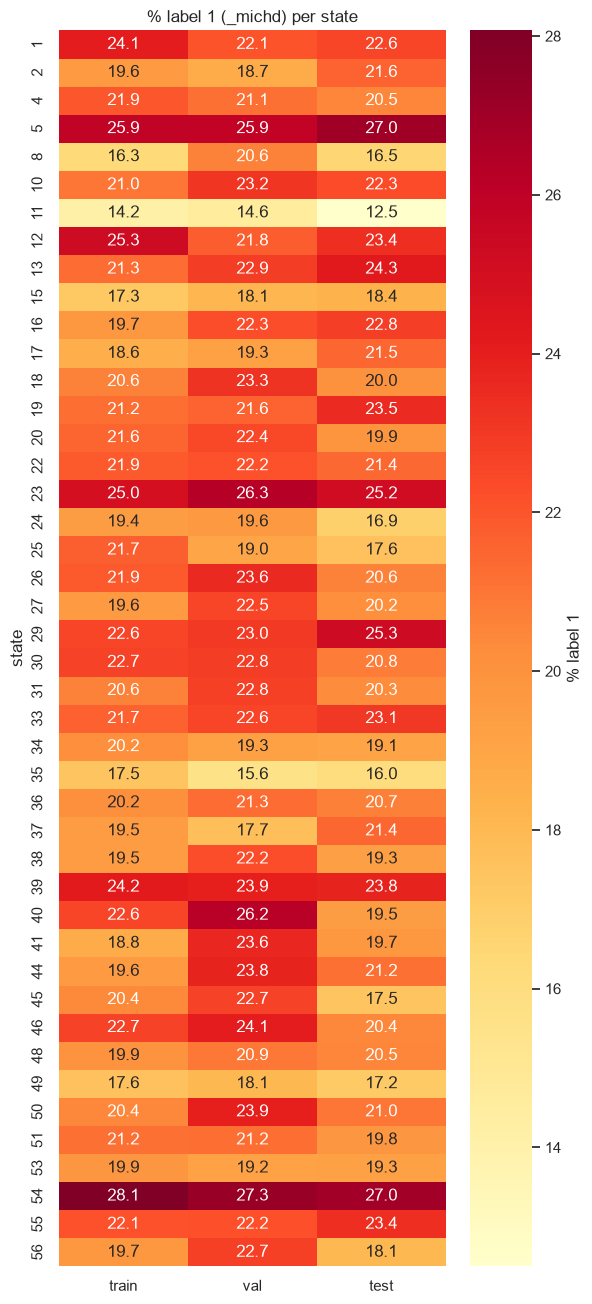

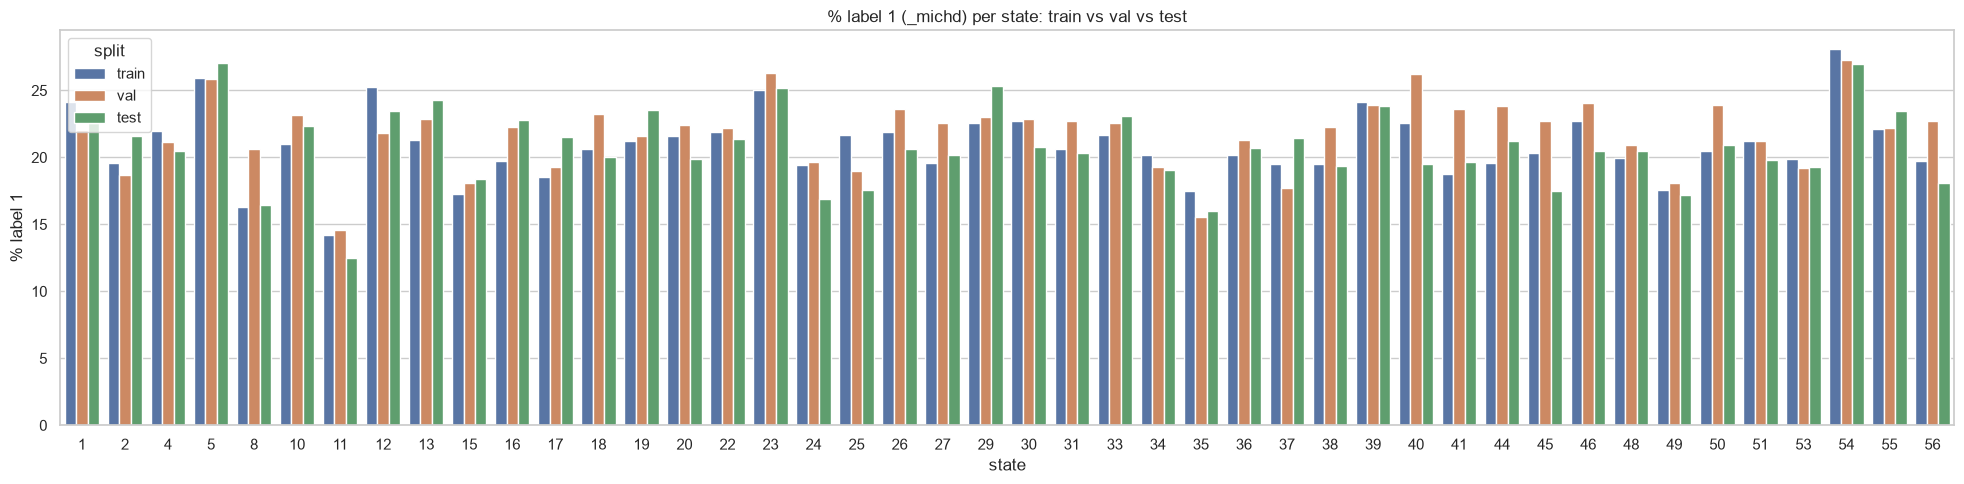

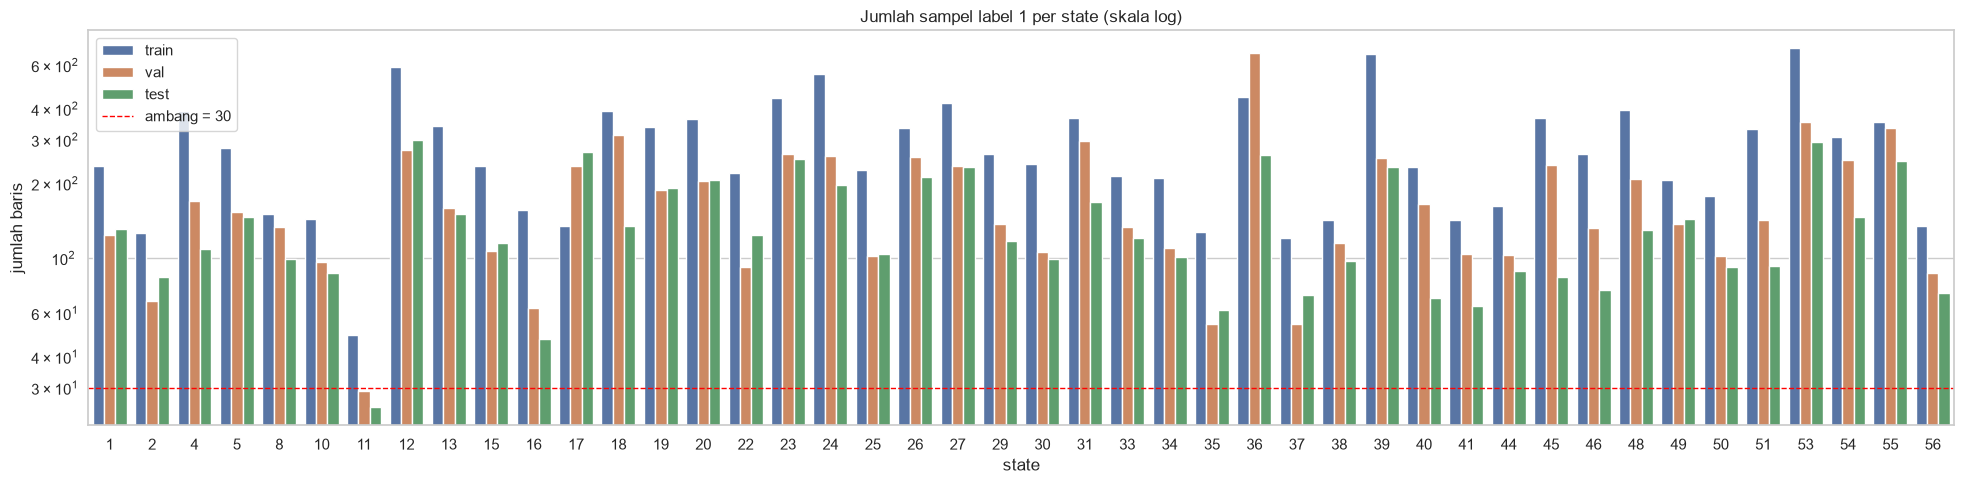

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
# %% 8. Plot distribusi label per state
sns.set_theme(style='whitegrid')
SPLIT_ORDER = ['train', 'val', 'test']
n_state = len(banding)
 
# 8a. Heatmap: % kelas minoritas per state (baris = state, kolom = split)
fig, ax = plt.subplots(figsize=(6, max(6, n_state * 0.3)))
sns.heatmap(banding[SPLIT_ORDER], annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': f'% label {kelas_minor}'}, ax=ax)
ax.set_title(f'% label {kelas_minor} ({TARGET}) per state')
ax.set_xlabel('')
plt.tight_layout()
plt.show()
 
# 8b. Bar chart berkelompok: % kelas minoritas per state, dibandingkan antar split
long_pct = (banding[SPLIT_ORDER].reset_index()
            .melt(id_vars='state', var_name='split', value_name='persen'))
fig, ax = plt.subplots(figsize=(max(12, n_state * 0.45), 5))
sns.barplot(data=long_pct, x='state', y='persen', hue='split',
            hue_order=SPLIT_ORDER, ax=ax)
ax.set_title(f'% label {kelas_minor} ({TARGET}) per state: train vs val vs test')
ax.set_ylabel(f'% label {kelas_minor}')
ax.set_xlabel('state')
plt.tight_layout()
plt.show()
 
# 8c. Jumlah sampel kelas minoritas per state (skala log) + garis ambang MIN_N
long_n = (jumlah_minor[SPLIT_ORDER].reset_index()
          .melt(id_vars='state', var_name='split', value_name='jumlah'))
fig, ax = plt.subplots(figsize=(max(12, n_state * 0.45), 5))
sns.barplot(data=long_n, x='state', y='jumlah', hue='split',
            hue_order=SPLIT_ORDER, ax=ax)
ax.set_yscale('log')
ax.axhline(MIN_N, color='red', linestyle='--', linewidth=1, label=f'ambang = {MIN_N}')
ax.set_title(f'Jumlah sampel label {kelas_minor} per state (skala log)')
ax.set_ylabel('jumlah baris')
ax.set_xlabel('state')
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
OUTPUT_DIR = BASE / 'split'   # folder tujuan penyimpanan CSV
# %% 9. Simpan train / val / test ke CSV
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
 
file_out = {
    'train': OUTPUT_DIR / 'data_train.csv',
    'val':   OUTPUT_DIR / 'data_val.csv',
    'test':  OUTPUT_DIR / 'data_test.csv',
}
 
for name, path in file_out.items():
    splits[name].to_csv(path, index=False)
 
# Verifikasi: baca ulang & bandingkan jumlah baris/kolom
print("=== FILE TERSIMPAN ===")
for name, path in file_out.items():
    cek = pd.read_csv(path)
    assert cek.shape == splits[name].shape, f"Shape {name} tidak cocok setelah disimpan!"
    print(f"{name:5s} | {cek.shape[0]:>6} baris x {cek.shape[1]} kolom | {path}")
print("\n✅ Semua file berhasil disimpan")

=== FILE TERSIMPAN ===
train |  59971 baris x 72 kolom | C:\Users\s2\Documents\FIXRKI\bfprssprep\split\data_train.csv
val   |  35679 baris x 72 kolom | C:\Users\s2\Documents\FIXRKI\bfprssprep\split\data_val.csv
test  |  29368 baris x 72 kolom | C:\Users\s2\Documents\FIXRKI\bfprssprep\split\data_test.csv

✅ Semua file berhasil disimpan


In [20]:
CLIENT_DIR = OUTPUT_DIR / 'clients'   # folder data per state (client)
# %% 10. Pisahkan data per state (1 state = 1 client federated learning)
# 10a. Bagi tiap split berdasarkan state -> clients[state][split]
all_states = sorted(set().union(*[set(d[STATE_COL].astype(int)) for d in splits.values()]))
 
clients = {}
for st in all_states:
    clients[st] = {
        name: d[d[STATE_COL].astype(int) == st].reset_index(drop=True)
        for name, d in splits.items()
    }
 
# 10b. Ringkasan tiap client
ringkas = []
for st, parts in clients.items():
    row = {'state': st}
    for name, d in parts.items():
        row[f'n_{name}']     = len(d)
        row[f'minor_{name}'] = int((d[TARGET] == kelas_minor).sum())
    ringkas.append(row)
ringkas = pd.DataFrame(ringkas).set_index('state')
ringkas['n_total'] = ringkas[['n_train', 'n_val', 'n_test']].sum(axis=1)
 
print(f"Jumlah client (state): {len(clients)}")
print(ringkas.to_string())
 
# 10c. Client yang bermasalah: split kosong, atau kelas minoritas < MIN_N
kosong = ringkas[(ringkas[['n_train', 'n_val', 'n_test']] == 0).any(axis=1)]
sedikit = ringkas[(ringkas[['minor_train', 'minor_val', 'minor_test']] < MIN_N).any(axis=1)]
print("\nClient dengan split kosong:", list(kosong.index) if len(kosong) else "Tidak ada")
print(f"Client dengan label {kelas_minor} < {MIN_N} di salah satu split:",
      list(sedikit.index) if len(sedikit) else "Tidak ada")
 
# 10d. Simpan: clients/state_XX/{train,val,test}.csv + ringkasan
for st, parts in clients.items():
    folder = CLIENT_DIR / f'state_{st:02d}'
    folder.mkdir(parents=True, exist_ok=True)
    for name, d in parts.items():
        d.to_csv(folder / f'{name}.csv', index=False)
ringkas.to_csv(CLIENT_DIR / 'ringkasan_client.csv')
 
# 10e. Verifikasi: total baris semua client == total baris tiap split
for name, d in splits.items():
    total_client = sum(len(parts[name]) for parts in clients.values())
    assert total_client == len(d), f"Jumlah baris {name} tidak cocok setelah dipisah per state!"
print(f"\n✅ {len(clients)} client tersimpan di {CLIENT_DIR}")

Jumlah client (state): 44
       n_train  minor_train  n_val  minor_val  n_test  minor_test  n_total
state                                                                     
1          979          236    562        124     581         131     2122
2          644          126    358         67     389          84     1391
4         1781          391    804        170     532         109     3117
5         1076          279    595        154     544         147     2215
8          927          151    646        133     601          99     2174
10         686          144    414         96     390          87     1490
11         345           49    199         29     200          25      744
12        2330          589   1257        274    1276         299     4863
13        1605          342    695        159     622         151     2922
15        1361          235    591        107     626         115     2578
16         791          156    283         63     206          47     1280